In [13]:
'''Project 21: Logistic Regression From Scratch

Assigned to: SANTHOSH
Employee ID: TFTPL434
Project Number: 21

Objective

The objective of this project is to implement a binary classification model using NumPy, Pandas, and Matplotlib, 
progressing from fundamental data analysis concepts to advanced machine learning techniques without relying on 
pre-built machine learning libraries.

The project begins with generating a synthetic student dataset containing study hours, practice scores, and pass/fail labels. 
It applies fundamental data analysis techniques, including DataFrame creation, data inspection, random sampling, and feature selection using Pandas.

The implementation then explores advanced numerical computing concepts using NumPy, including array operations, 
matrix multiplication, statistical calculations, feature standardization, and vectorized computations. 
A logistic regression model is developed from scratch using the sigmoid function, binary cross-entropy (log-loss),
and gradient descent to optimize model weights and bias over multiple training epochs.

Model performance is evaluated using training and testing accuracy, a confusion matrix, precision, and recall. 
The learned coefficients are interpreted using odds ratios to understand the relationship between student features and predicted outcomes.

Finally, Matplotlib is used to visualize the decision boundary, training and testing loss curves, and confusion matrix. 
The project also demonstrates reproducible experimentation, result interpretation, and file handling by exporting 
visualizations to `chart.png` and evaluation metrics to `results.json`.

Key Learning Outcome: Develop a practical understanding of machine learning fundamentals, 
optimization, model evaluation, and data visualization by implementing logistic regression entirely from scratch.'''




'Project 21: Logistic Regression From Scratch\n\nAssigned to: SANTHOSH\nEmployee ID: TFTPL434\nProject Number: 21\n\nObjective\n\nThe objective of this project is to implement a binary classification model using NumPy, Pandas, and Matplotlib, \nprogressing from fundamental data analysis concepts to advanced machine learning techniques without relying on \npre-built machine learning libraries.\n\nThe project begins with generating a synthetic student dataset containing study hours, practice scores, and pass/fail labels. \nIt applies fundamental data analysis techniques, including DataFrame creation, data inspection, random sampling, and feature selection using Pandas.\n\nThe implementation then explores advanced numerical computing concepts using NumPy, including array operations, \nmatrix multiplication, statistical calculations, feature standardization, and vectorized computations. \nA logistic regression model is developed from scratch using the sigmoid function, binary cross-entropy

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv("student_exam_data.csv")
df

,Study Hours,Previous Exam Score,Pass/Fail
0,4.370861,81.889703,0
1,9.556429,72.165782,1
2,7.587945,58.571657,0
3,6.387926,88.827701,1
4,2.404168,81.083870,0
...,...,...,...
495,4.180170,45.494924,0
496,6.252905,95.038815,1
497,1.699612,48.209118,0
498,9.769553,97.014241,1


In [16]:
print(df.head())
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df["Pass/Fail"].value_counts())

   Study Hours  Previous Exam Score  Pass/Fail
0     4.370861            81.889703          0
1     9.556429            72.165782          1
2     7.587945            58.571657          0
3     6.387926            88.827701          1
4     2.404168            81.083870          0
(500, 3)
Index(['Study Hours', 'Previous Exam Score', 'Pass/Fail'], dtype='object')
Study Hours            float64
Previous Exam Score    float64
Pass/Fail                int64
dtype: object
Pass/Fail
0    316
1    184
Name: count, dtype: int64


In [21]:
X = df[["Study Hours", "Previous Exam Score"]].to_numpy()
y = df["Pass/Fail"].to_numpy()
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFirst 5 feature records:")
print(X[0:5])
print("\nFirst 5 target values:")
print(y[0:5])

#Why?
#X contains 500 rows and 2 features.
#y contains 500 corresponding labels.
#Each row in X matches the label in the same position in y.


Features shape: (500, 2)
Target shape: (500,)

First 5 feature records:
[[ 4.37086107 81.88970284]
 [ 9.55642876 72.16578198]
 [ 7.58794548 58.57165698]
 [ 6.38792636 88.82770118]
 [ 2.40416776 81.08387035]]

First 5 target values:
[0 1 0 1 0]


In [26]:
# Display the first 10 target values
print(y[:10])
# Count the number of students in each class
print(np.bincount(y))

[0 1 0 1 0 0 0 1 1 1]
[316 184]


In [29]:
# Create indices for all 500 records
indices = np.arange(len(X))
print("Original indices:")
print(indices[:10])
# Randomly shuffle the indices
np.random.seed(42)
np.random.shuffle(indices)
print("Shuffled indices:")
print(indices[:10])

Original indices:
[0 1 2 3 4 5 6 7 8 9]
Shuffled indices:
[361  73 374 155 104 394 377 124  68 450]


In [32]:
# Now that we understand indices, we can divide the 500 records into training and testing sets.
# Calculate the training size
split_index = int(0.75 * len(X))

# Divide the indices
train_indices = indices[:split_index]
test_indices = indices[split_index:]

# Select the corresponding features
X_train = X[train_indices]
X_test = X[test_indices]

# Select the corresponding target labels
y_train = y[train_indices]
y_test = y[test_indices]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (375, 2)
Testing features: (125, 2)
Training targets: (375,)
Testing targets: (125,)


In [33]:
# Calculate the mean of each feature
mean = np.mean(X_train, axis=0)
# Calculate the standard deviation of each feature
std = np.std(X_train, axis=0)
print("Mean:", mean)
print("Standard deviation:", std)

Mean: [ 5.42996727 69.34878927]
Standard deviation: [ 2.69999598 17.26127302]


In [34]:
# Standardize training features
X_train_scaled = (X_train - mean) / std

# Standardize testing features using training statistics
X_test_scaled = (X_test - mean) / std

print("First 5 standardized training records:")
print(X_train_scaled[:5])

print("\nStandardized training mean:")
print(np.mean(X_train_scaled, axis=0))

print("\nStandardized training standard deviation:")
print(np.std(X_train_scaled, axis=0))

First 5 standardized training records:
[[ 0.50356619 -0.12464082]
 [ 1.07747775  0.46209875]
 [-1.40343522 -1.61202525]
 [-0.83387896 -1.25680018]
 [ 1.38449502 -1.28093895]]

Standardized training mean:
[-1.97175609e-16  1.74012656e-15]

Standardized training standard deviation:
[1. 1.]


In [35]:
print("Standard deviations:", std)
print("Any zero standard deviation:", np.any(std == 0))

Standard deviations: [ 2.69999598 17.26127302]
Any zero standard deviation: False


In [36]:
#First, finish checking the standardization we already performed.

print("Training mean:")
print(np.mean(X_train_scaled, axis=0))

print("\nTraining standard deviation:")
print(np.std(X_train_scaled, axis=0))

print("\nFirst 5 standardized records:")
print(X_train_scaled[:5])

Training mean:
[-1.97175609e-16  1.74012656e-15]

Training standard deviation:
[1. 1.]

First 5 standardized records:
[[ 0.50356619 -0.12464082]
 [ 1.07747775  0.46209875]
 [-1.40343522 -1.61202525]
 [-0.83387896 -1.25680018]
 [ 1.38449502 -1.28093895]]


In [37]:
#Implement the Sigmoid Function
#Logistic regression converts the score into a probability using the sigmoid function.
#σ(z)=1/(1+e^−z)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print("Score 0:", sigmoid(0))
print("Score 2:", sigmoid(2))
print("Score -2:", sigmoid(-2))

Score 0: 0.5
Score 2: 0.8807970779778823
Score -2: 0.11920292202211755


In [38]:
#Calculate Scores for Y Training Data
#Now let's apply matrix multiplication to your actual training data.

# Initialize temporary weights and bias
weights = np.zeros(X_train_scaled.shape[1])
bias = 0.0

# Calculate scores
z = np.dot(X_train_scaled, weights) + bias

print("First 5 scores:")
print(z[:5])

print("\nScore shape:", z.shape)

First 5 scores:
[0. 0. 0. 0. 0.]

Score shape: (375,)


In [41]:
import numpy as np

y_actual = np.array([1, 0, 1, 0])
y_probability = np.array([0.9, 0.2, 0.8, 0.1])

epsilon = 1e-15

y_probability = np.clip(
    y_probability,
    epsilon,
    1 - epsilon
)

loss = -np.mean(
    y_actual * np.log(y_probability)
    + (1 - y_actual) * np.log(1 - y_probability)
)

print("Log Loss:", loss)

Log Loss: 0.16425203348601802


In [42]:
#Create a Reusable Log Loss Function
#We'll need this function throughout training.

def log_loss(y_true, y_probability):
    epsilon = 1e-15

    y_probability = np.clip(
        y_probability,
        epsilon,
        1 - epsilon
    )

    loss = -np.mean(
        y_true * np.log(y_probability)
        + (1 - y_true) * np.log(1 - y_probability)
    )

    return loss

In [43]:
print(log_loss(y_actual, y_probability))

0.16425203348601802


In [61]:
#Implementing the training function
def train_logistic_regression(
    X_train, y_train, X_test, y_test,
    learning_rate=0.1, epochs=1000
):
    m, n = X_train.shape

    weights = np.zeros(n)
    bias = 0.0

    train_loss_history = []
    test_loss_history = []

    for epoch in range(epochs):

        # Training predictions
        z_train = np.dot(X_train, weights) + bias
        train_probabilities = sigmoid(z_train)

        # Calculate gradients
        error = train_probabilities - y_train
        dw = np.dot(X_train.T, error) / m
        db = np.mean(error)

        # Update weights and bias
        weights -= learning_rate * dw
        bias -= learning_rate * db

        # Calculate training loss using updated parameters
        z_train = np.dot(X_train, weights) + bias
        train_probabilities = sigmoid(z_train)
        train_loss = log_loss(y_train, train_probabilities)

        # Calculate test loss using the same updated parameters
        z_test = np.dot(X_test, weights) + bias
        test_probabilities = sigmoid(z_test)
        test_loss = log_loss(y_test, test_probabilities)

        # Store both losses
        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)

    return weights, bias, train_loss_history, test_loss_history

In [77]:
#now train our model
weights, bias, train_loss_history, test_loss_history = (
    train_logistic_regression(
        X_train_scaled,
        y_train,
        X_test_scaled,
        y_test,
        learning_rate=0.1,
        epochs=1000
    )
)

In [78]:
#Convert Probabilities into Predictions
#The model produces probabilities, but our target contains 0 and 1.
#We use a threshold of 0.5 to convert probabilities into classes.

def predict(X, weights, bias):
    z = np.dot(X, weights) + bias
    probabilities = sigmoid(z)

    predictions = (probabilities >= 0.5).astype(int)

    return predictions


In [79]:
#Test the prediction function
y_train_pred = predict(X_train_scaled, weights, bias)
y_test_pred = predict(X_test_scaled, weights, bias)

print("First 10 actual labels:")
print(y_test[:10])

print("\nFirst 10 predicted labels:")
print(y_test_pred[:10])

First 10 actual labels:
[1 0 0 0 0 0 0 1 1 1]

First 10 predicted labels:
[1 0 0 0 0 0 0 1 0 0]


In [80]:
#Confusion Matrix
#We'll implement the metrics directly using NumPy.

def evaluate_model(y_true, y_pred):

    # Calculate confusion matrix components
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    # Calculate accuracy
    accuracy = (tp + tn) / len(y_true)

    # Calculate precision
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0

    # Calculate recall
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    # Construct confusion matrix
    confusion_matrix = np.array([
        [tn, fp],
        [fn, tp]
    ])

    return accuracy, precision, recall, confusion_matrix

In [81]:
#Evaluate your test predictions
accuracy, precision, recall, cm = evaluate_model(
    y_test,
    y_test_pred
)

print("Test Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")

print("\nConfusion Matrix:")
print(cm)

Test Accuracy: 84.8 %
Precision: 80.95 %
Recall: 75.56 %

Confusion Matrix:
[[72  8]
 [11 34]]


In [82]:
#Evaluate the Logistic Regression Model

import numpy as np

def evaluate_model(y_true, y_pred):

    # Count correct and incorrect predictions
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    # Calculate accuracy
    accuracy = (tp + tn) / len(y_true)

    # Calculate precision
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0

    # Calculate recall
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    # Create confusion matrix
    cm = np.array([
        [tn, fp],
        [fn, tp]
    ])

    return accuracy, precision, recall, cm


accuracy, precision, recall, cm = evaluate_model(
    y_test, y_test_pred
)

print("Test Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")

print("\nConfusion Matrix:")
print(cm)

Test Accuracy: 84.8 %
Precision: 80.95 %
Recall: 75.56 %

Confusion Matrix:
[[72  8]
 [11 34]]


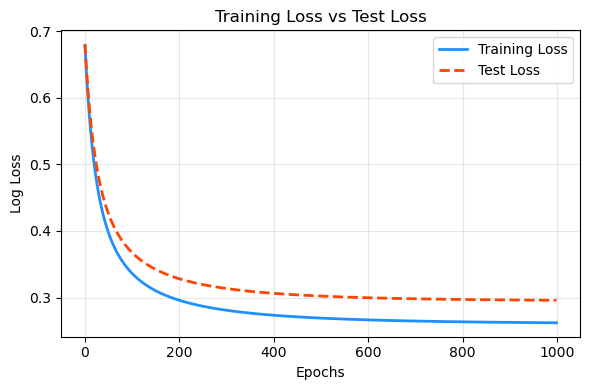

In [137]:
# Plot the Training and Test Loss Curves
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

# Solid blue line
plt.plot(
    train_loss_history,
    label="Training Loss",
    color="dodgerblue",
    linestyle="-",
    linewidth=2
)

# Dotted orange line
plt.plot(
    test_loss_history,
    label="Test Loss",
    color="orangered",
    linestyle="dashed",
    linewidth=2
)

plt.title("Training Loss vs Test Loss")
plt.xlabel("Epochs")
plt.ylabel("Log Loss")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

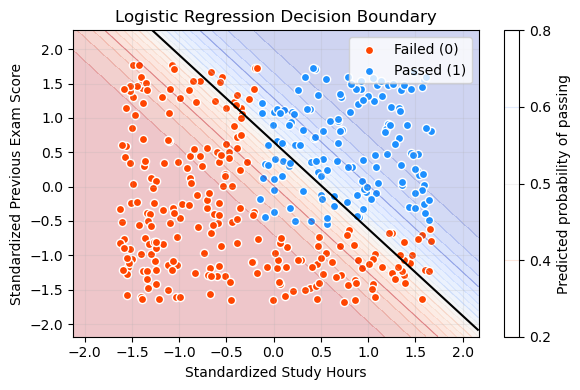

In [142]:
import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# STEP 1: Separate the standardized training features
# ==================================================

x1 = X_train_scaled[:, 0]
x2 = X_train_scaled[:, 1]


# ==================================================
# STEP 2: Create the grid for the decision boundary
# ==================================================

x1_min, x1_max = x1.min() - 0.5, x1.max() + 0.5
x2_min, x2_max = x2.min() - 0.5, x2.max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x1_min, x1_max, 200),
    np.linspace(x2_min, x2_max, 200)
)


# ==================================================
# STEP 3: Calculate predicted probabilities
# ==================================================

grid_scaled = np.c_[xx.ravel(), yy.ravel()]

z_grid = np.dot(grid_scaled, weights) + bias

probabilities_grid = sigmoid(z_grid).reshape(xx.shape)


# ==================================================
# STEP 4: Create the plot
# ==================================================

plt.figure(figsize=(6, 4))


# ==================================================
# STEP 5: Plot the probability background
# ==================================================

plt.contourf(
    xx,
    yy,
    probabilities_grid,
    levels=np.linspace(0, 1, 21),
    cmap="coolwarm_r",
    alpha=0.25
)


# ==================================================
# STEP 6: Add probability contour lines
# ==================================================

contours = plt.contour(
    xx,
    yy,
    probabilities_grid,
    levels=[0.2, 0.4, 0.5, 0.6, 0.8],
    cmap="coolwarm_r",
    alpha=0.35,
    linewidths=0.8
)


# ==================================================
# STEP 7: Highlight the decision boundary at 0.5
# ==================================================

plt.contour(
    xx,
    yy,
    probabilities_grid,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)


# ==================================================
# STEP 8: Plot actual failed and passed students
# ==================================================

plt.scatter(
    x1[y_train == 0],
    x2[y_train == 0],
    color="orangered",
    label="Failed (0)",
    marker="o",
    edgecolors="white",
    s=35
)

plt.scatter(
    x1[y_train == 1],
    x2[y_train == 1],
    color="dodgerblue",
    label="Passed (1)",
    marker="o",
    edgecolors="white",
    s=35
)


# ==================================================
# STEP 9: Add labels, title, and legend
# ==================================================

plt.title("Logistic Regression Decision Boundary")
plt.xlabel("Standardized Study Hours")
plt.ylabel("Standardized Previous Exam Score")

plt.colorbar(
    contours,
    label="Predicted probability of passing"
)

plt.legend(loc="upper right")
plt.grid(True, alpha=0.2)


# ==================================================
# STEP 10: Save and display the chart
# ==================================================

plt.tight_layout()

plt.savefig(
    "decision_boundary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

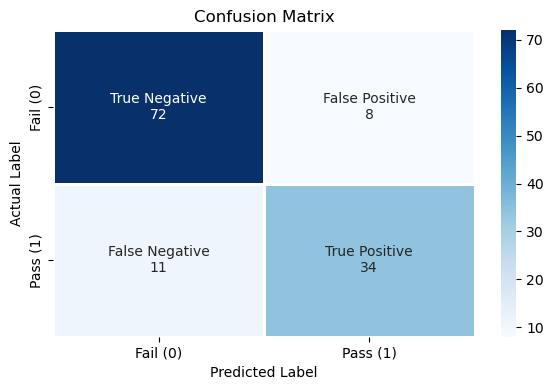

In [149]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

# Labels with counts
labels = np.array([
    [f"True Negative\n{cm[0, 0]}", f"False Positive\n{cm[0, 1]}"],
    [f"False Negative\n{cm[1, 0]}", f"True Positive\n{cm[1, 1]}"]
])

# Plot confusion matrix
sns.heatmap(
    cm,
    annot=labels,
    fmt="",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    xticklabels=["Fail (0)", "Pass (1)"],
    yticklabels=["Fail (0)", "Pass (1)"],
    cbar=True
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


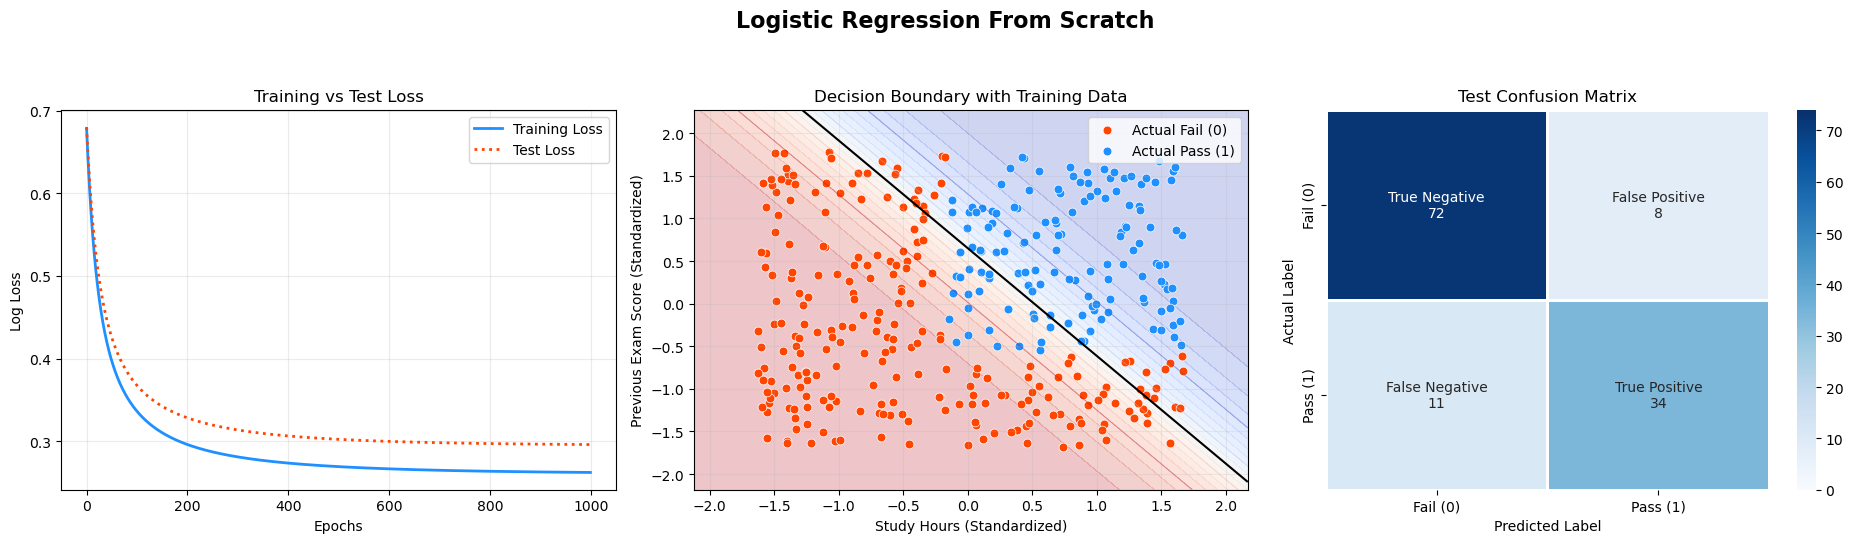

Chart saved successfully!
File location: C:\Users\santhosh\Logistic_Regression_PassFail_Prediction\chart.png
File size: 814.19 KB
File exists: True


In [159]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ==================================================
# STEP 1: CREATE THE COMBINED FIGURE
# ==================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))


# ==================================================
# STEP 2: TRAINING AND TEST LOSS CURVES
# ==================================================

axes[0].plot(
    train_loss_history,
    color="dodgerblue",
    linestyle="-",
    linewidth=2,
    label="Training Loss"
)

axes[0].plot(
    test_loss_history,
    color="orangered",
    linestyle=":",
    linewidth=2,
    label="Test Loss"
)

axes[0].set_title("Training vs Test Loss")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Log Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.25)


# ==================================================
# STEP 3: PREPARE THE DECISION-BOUNDARY GRID
# ==================================================

x1 = X_train_scaled[:, 0]
x2 = X_train_scaled[:, 1]

x1_min, x1_max = x1.min() - 0.5, x1.max() + 0.5
x2_min, x2_max = x2.min() - 0.5, x2.max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x1_min, x1_max, 200),
    np.linspace(x2_min, x2_max, 200)
)


# ==================================================
# STEP 4: CALCULATE MODEL PROBABILITIES
# ==================================================

grid_scaled = np.c_[xx.ravel(), yy.ravel()]

z_grid = np.dot(grid_scaled, weights) + bias

probabilities_grid = sigmoid(z_grid).reshape(xx.shape)


# ==================================================
# STEP 5: DISPLAY THE PROBABILITY BACKGROUND
# ==================================================

axes[1].contourf(
    xx,
    yy,
    probabilities_grid,
    levels=np.linspace(0, 1, 21),
    cmap="coolwarm_r",
    alpha=0.25
)

# Probability contour lines
axes[1].contour(
    xx,
    yy,
    probabilities_grid,
    levels=[0.2, 0.4, 0.6, 0.8],
    cmap="coolwarm_r",
    alpha=0.35,
    linewidths=0.8
)

# Decision boundary: predicted probability = 0.5
axes[1].contour(
    xx,
    yy,
    probabilities_grid,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)


# ==================================================
# STEP 6: DISPLAY ACTUAL TRAINING RECORDS
# ==================================================

# Actual failed students
axes[1].scatter(
    X_train_scaled[y_train == 0, 0],
    X_train_scaled[y_train == 0, 1],
    color="orangered",
    marker="o",
    edgecolors="white",
    linewidths=0.5,
    s=40,
    label="Actual Fail (0)"
)

# Actual passed students
axes[1].scatter(
    X_train_scaled[y_train == 1, 0],
    X_train_scaled[y_train == 1, 1],
    color="dodgerblue",
    marker="o",
    edgecolors="white",
    linewidths=0.5,
    s=40,
    label="Actual Pass (1)"
)

axes[1].set_title("Decision Boundary with Training Data")
axes[1].set_xlabel("Study Hours (Standardized)")
axes[1].set_ylabel("Previous Exam Score (Standardized)")
axes[1].legend()
axes[1].grid(True, alpha=0.2)


# ==================================================
# STEP 7: DISPLAY THE TEST CONFUSION MATRIX
# ==================================================

# Matrix layout: [[TN, FP], [FN, TP]]

labels = np.array([
    [f"True Negative\n{cm[0, 0]}", f"False Positive\n{cm[0, 1]}"],
    [f"False Negative\n{cm[1, 0]}", f"True Positive\n{cm[1, 1]}"]
])

sns.heatmap(
    cm,
    annot=labels,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=max(int(cm.max()) + 2, 1),
    linewidths=1,
    linecolor="white",
    xticklabels=["Fail (0)", "Pass (1)"],
    yticklabels=["Fail (0)", "Pass (1)"],
    cbar=True,
    ax=axes[2]
)

axes[2].set_title("Test Confusion Matrix")
axes[2].set_xlabel("Predicted Label")
axes[2].set_ylabel("Actual Label")


# ==================================================
# STEP 8: ADD THE MAIN TITLE
# ==================================================

fig.suptitle(
    "Logistic Regression From Scratch",
    fontsize=16,
    fontweight="bold"
)


# ==================================================
# STEP 9: SAVE THE FINAL CHART
# ==================================================

fig.tight_layout(rect=[0, 0, 1, 0.93])

output_path = os.path.abspath("chart.png")

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ==================================================
# STEP 10: CONFIRM THE SAVED FILE
# ==================================================

print("Chart saved successfully!")
print("File location:", output_path)
print(
    "File size:",
    round(os.path.getsize(output_path) / 1024, 2),
    "KB"
)
print("File exists:", os.path.exists(output_path))



In [154]:
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("\nConfusion Matrix:\n", cm)

Accuracy: 0.848
Precision: 0.8095238095238095
Recall: 0.7555555555555555

Confusion Matrix:
 [[72  8]
 [11 34]]
